<a href="https://colab.research.google.com/github/Prathamesh-kadam/LSST-Alert-Broker-/blob/main/how_to_query_ANT_DB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
__author__ = "M. Soraisam and the ANTARES team <antares@noirlab.edu>"
__version__= "20261102" #yyyymmdd

# The ANTARES value-added alert database: How to query and perform scientific analysis

## Table of Contents
1. [Introduction](#Introduction)
2. [Anatomy of an object in ANTARES database](#Anatomy-of-an-object-in-ANTARES-database)
3. [Key method to search ANTARES database](#Key-method-to-search-ANTARES-database)
4. [Example use cases](#Example-use-cases)<br>
   a) [Retrieve a locus and associated alerts](#a\)-Retrieve-a-locus-and-associated-alerts)<br>
   b) [Find supernovae, AGNs, and variable stars based on cross-matching results](#b\)-Find-supernovae,-AGNs,-and-variable-stars-based-on-cross-matching-results)<br>
5. [Exercises](#Exercises)

# Introduction

ANTARES receives alerts from surveys in real-time and sends them through a processing pipeline, which includes aggregating the alerts into loci (fixed sky positions), cross-matching with several legacy catalogs and user-supplied watch lists, and running science filters contributed by the community. As a result, every alert is enriched with additional properties that help users decide which targets to follow up.

Here we will learn how to explore the value-added alert database of ANTARES using its [client library](<https://nsf-noirlab.gitlab.io/csdc/antares/client/>).   

Additionally, here is the link to the [ANTARES portal](<https://antares.noirlab.edu>).




<div class="alert alert-block alert-warning">
⚠️ <b>Note:</b> Very recently there has been intermittent 500 errors while accessing the ANTARES portal. Our software engineers are aware of the issue and are actively working on a fix. Alert processing and the underlying data should not be affected.
</div>

### Install the `antares-client`
Once installed, comment out the following cell.

In [ ]:
#!pip install antares-client

#### Also install plotting packages to use in this notebook

In [ ]:
#!pip install ipympl matplotlib

# Anatomy of an object in ANTARES database

The ANTARES database consists of:
1) Alerts and their [properties](<https://antares.noirlab.edu/properties>), including ANTARES standardized properties ("**ant_**" prefixed) and those contained in the alert packets sent by the corresponding surveys
2) Loci and their [properties](<https://antares.noirlab.edu/properties>), including light curves, [cross-matched objects](<https://antares.noirlab.edu/catalogs>) and derived properties from user-contributed science filters


# Key method to search ANTARES database

You can query the ANTARES database in various ways. For example:
- ID of the object
- Cone search
- Science filter labels, aka "*tags*"
- Catalog cross-matches
- Advanced ElasticSearch queries  
- Gravitational wave notics

All of these searches are enabled by the [`antares_client.search` module](<https://nsf-noirlab.gitlab.io/csdc/antares/client/tutorial/searching.html>).

# Example use cases

Below we will use the `antares_client` library to explore a few use cases.

## a) Retrieve a locus and associated alerts

Let's pull the data of the Rubin LSST DiaObject with Id **170587116668452890** from the ANTARES database. The locus page of this object is [linked here](<https://antares.noirlab.edu/loci/ANT2026npt356di5pkp>). Note that ANTARES also assigns a unique identifier prefixed with "**ANT**" to each object in its database. For this LSST object, it is ANT2026npt356di5pkp. Besides the survey-provided object Id, you can use the ANTARES Id to retrieve the data.  

#### Imports

In [ ]:
from antares_client.search import get_by_id, get_by_lsst_dia_object_id
from antares_client.search import search
from pprint import pprint
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time
from itertools import islice

#### Pull data by ID



<div class="alert alert-block alert-warning">
⚠️ <b>Note:</b> If you get an error while retrieving by LSST DiaObject Id, use the ANTARES Id instead.
</div>

In [ ]:
# Retrieve by ANTARES ID
# locus = get_by_id("ANT2026npt356di5pkp")

# Retrieve by LSST Dia Object ID
locus = get_by_lsst_dia_object_id("170587116668452890")

#### Coordinates

In [ ]:
# Show its coordinates
print (f"Position of ANTARES locus {locus.locus_id}: {locus.ra}, {locus.dec}")

Position of ANTARES locus ANT2026npt356di5pkp: 9.330441172612284, -44.43204809865222


#### Latest alert properties

In [ ]:
# Show its latest alert
print (f"Latest alert of ANTARES locus {locus.locus_id}\n")
alerts_list = locus.alerts
latest_alert = alerts_list[-1]
print (f"Alert Id {latest_alert.alert_id}\nTimestamp: {latest_alert.mjd}\nProperties:")
pprint (latest_alert.properties)

Latest alert of ANTARES locus ANT2026npt356di5pkp

Alert Id lsst:170666302155259979
Timestamp: 61235.402308887264
Properties:
{'ant_dec': -44.4320399350981,
 'ant_mag': 21.50865344187777,
 'ant_magerr': 0.047698723680175074,
 'ant_maglim': 21.50865344187777,
 'ant_mjd': 61235.402308887264,
 'ant_passband': 'i',
 'ant_ra': 9.33044854498584,
 'ant_survey': 4,
 'ant_time_received': 1784022192,
 'lsst_diaObject_dec': -44.43205022046006,
 'lsst_diaObject_decErr': 6.673121788480785e-07,
 'lsst_diaObject_diaObjectId': 170587116668452890,
 'lsst_diaObject_g_psfFluxErrMean': 327.78955078125,
 'lsst_diaObject_g_psfFluxMax': 6298.4716796875,
 'lsst_diaObject_g_psfFluxMaxSlope': 1366265.25,
 'lsst_diaObject_g_psfFluxMean': 4794.14892578125,
 'lsst_diaObject_g_psfFluxMeanErr': 60.717464447021484,
 'lsst_diaObject_g_psfFluxMin': 2710.92333984375,
 'lsst_diaObject_g_psfFluxNdata': 8,
 'lsst_diaObject_g_psfFluxSigma': 1191.47509765625,
 'lsst_diaObject_g_scienceFluxMean': 5778.22119140625,
 'lsst_diaO

#### Cross-matched objects

In [ ]:
# Show its matched catalog objects
print (f"Cross-matched objects for ANTARES locus {locus.locus_id}\n")
pprint (locus.catalog_objects)

Cross-matched objects for ANTARES locus ANT2026npt356di5pkp

defaultdict(<class 'list'>,
            {'tns_public_objects': [{'creationdate': '2026-06-29T02:20:59',
                                     'declination': -44.43204846933,
                                     'discmagfilter': 163.0,
                                     'discoverydate': '2026-06-26T09:59:22',
                                     'discoverymag': 20.26,
                                     'filter': 'i',
                                     'internal_names': 'LSST-AP-DO-170587116668452890',
                                     'lastmodified': '2026-06-29T02:20:59',
                                     'name': '2026qqx',
                                     'name_prefix': 'AT',
                                     'objid': 211786,
                                     'ra': 9.330439804853,
                                     'redshift': None,
                                     'reporters': 'A. Chalagulla (UCSC

#### Available locus properties

In [ ]:
# Show its available property names and values
print (f"Available properties for ANTARES locus {locus.locus_id}\n")
pprint (locus.properties)

Available properties for ANTARES locus ANT2026npt356di5pkp

{'brightest_alert_id': 'lsst:170587116668452890',
 'brightest_alert_magnitude': 20.259246271084937,
 'brightest_alert_observation_time': 61217.4162284394,
 'feature_amplitude_magn_i': 0.624703585396416,
 'feature_amplitude_magn_z': 0.14285344327631755,
 'feature_anderson_darling_normal_flux_i': 0.7996037714024745,
 'feature_anderson_darling_normal_magn_i': 1.0727340310449838,
 'feature_bazin_fit_amplitude_i': 9774.0205078125,
 'feature_bazin_fit_baseline_i': 9047.708984374985,
 'feature_bazin_fit_fall_time_i': 8.993040223933349,
 'feature_bazin_fit_reduced_chi2_i': 2.1064936796058345e-63,
 'feature_bazin_fit_reference_time_i': 61217.4162284394,
 'feature_bazin_fit_rise_time_i': 8.993040223933349,
 'feature_beyond_1_std_magn_i': 0.15384615384615385,
 'feature_beyond_1_std_magn_z': 0.3333333333333333,
 'feature_beyond_2_std_magn_i': 0.0,
 'feature_beyond_2_std_magn_z': 0.0,
 'feature_bins_window1.0_offset0.0_eta_e_magn_i': 0.720

#### Associated science filter tags

In [ ]:
print (f"Tags for ANTARES locus {locus.locus_id}:\n{locus.tags}")

Tags for ANTARES locus ANT2026npt356di5pkp:
['lc_feature_extractor', 'young_rubin_transients', 'in_LSSTDDF', 'lsst_scimma_quality_transient', 'SN_candies']


#### Light curve

In [ ]:
# Plot the light curve
lc = locus.lightcurve
lc.head()

,time,alert_id,ant_mjd,ant_survey,ant_ra,ant_dec,ant_passband,ant_mag,ant_magerr,ant_maglim,ant_mag_corrected,ant_magerr_corrected,ant_magulim_corrected,ant_magllim_corrected
0,2026-06-26 09:59:22.137164,lsst:170587116668452890,61217.416228,4,9.330440,-44.432052,i,20.259246,0.008788,20.259246,20.196330,0.008713,NaN,NaN
1,2026-06-26 10:00:03.311304,lsst:170587116781699155,61217.416705,4,9.330439,-44.432049,i,20.288263,0.009072,20.288263,20.228811,0.008896,NaN,NaN
2,2026-06-26 10:05:30.434333,lsst:170587117339017350,61217.420491,4,9.330447,-44.432053,g,21.903530,0.016714,21.903530,21.771117,0.015356,NaN,NaN
3,2026-06-28 10:02:46.372078,lsst:170595944416411689,61219.418592,4,9.330440,-44.432045,i,20.291943,0.017746,20.291943,20.178677,0.016713,NaN,NaN
4,2026-06-28 10:03:29.277083,lsst:170595944549056543,61219.419089,4,9.330437,-44.432044,i,20.281912,0.017476,20.281912,20.169120,0.016396,NaN,NaN




<div class="alert alert-block alert-warning">
⚠️ <b>Note:</b> For transients, use <code>ant_mag</code> and <code>ant_magerr</code>, which are measured on the difference images. For persistent variable sources, use <code>ant_mag_corrected</code> and <code>ant_magerr_corrected</code>.
</div>

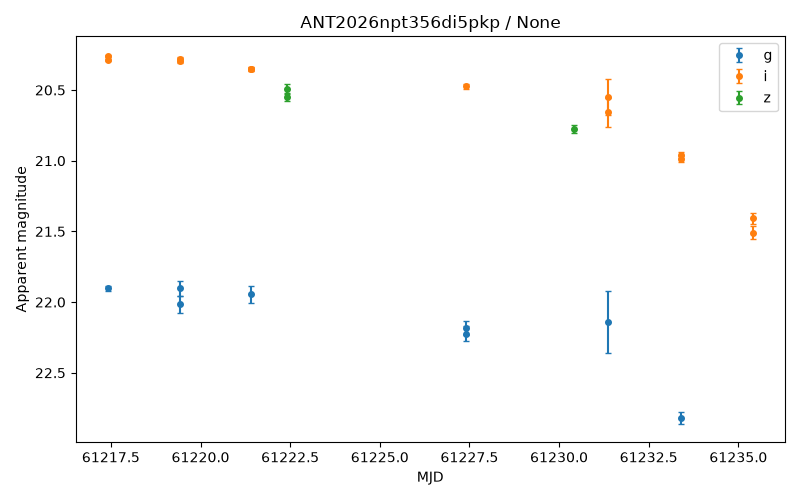

In [ ]:
plt.close('all')
fig, ax = plt.subplots(figsize=(8, 5))

for band, data in lc.groupby("ant_passband"):
    ax.errorbar(data["ant_mjd"], data["ant_mag"], yerr=data["ant_magerr"],
                     fmt="o", ms=4, capsize=2, label=band)

ax.invert_yaxis()
ax.set_xlabel("MJD")
ax.set_ylabel("Apparent magnitude")
ax.set_title(f"{locus.locus_id} / {locus.properties.get('')}")
ax.legend()
plt.tight_layout()
plt.show()


## b) Find supernovae, AGNs, and variable stars based on cross-matching results

We will use cross-matches with three catalogs to find different classes of objects in the ANTARES database:
- Transient Name Server (TNS) for supernovae
- Million Quasars catalog (Milliquas) for AGNs
- AAVSO International Variable Star Index (VSX) for variable stars


In [ ]:
query = {
    "query": {
        "bool": {
            "filter": {
                "bool": {
                    "must": [
                        {
                            "terms": {
                                "catalogs": [
                                    "tns_public_objects",
                                    "milliquas",
                                    "vsx"
                                ]
                            }
                        },
                        {
                            "exists": {
                                "field": "properties.survey.lsst"
                            }
                        },
                        {
                            "range": {
                                "properties.num_mag_values": {
                                    "gte": 10
                                }
                            }
                        },
                        {
                            "range": {
                                "properties.oldest_alert_observation_time": {
                                    "gte": float(Time("2026-02-24").mjd)
                                }
                            }
                        },
                        {
                            "range": {
                                "properties.newest_alert_observation_time": {
                                    "lte": float(Time("2026-07-15").mjd)
                                }
                            }
                        },
                    ]
                }
            }
        }
    }
}

In [ ]:
cat_cls = {
    "milliquas": "agn",
    "vsx": "var_star",    ## make sure VAR is not in catalog entry
    "tns_public_objects": "sne",
}

results = {cls: [] for cls in cat_cls.values()}

for locus in islice(search(query), 100):
    for cat, cls in cat_cls.items():
        if cat in locus.catalog_objects.keys():
            results[cls].append(locus.locus_id)
            break

In [ ]:
for k, v in results.items():
    print (k, len(v))

agn 20
var_star 10
sne 70


#### Let's look at one randomly selected object from each class in the ANTARES portal

In [ ]:
print (f"A possible AGN https://antares.noirlab.edu/loci/{np.random.choice(results["agn"])}\n")

print (f"A possible variable star https://antares.noirlab.edu/loci/{np.random.choice(results["var_star"])}\n")

print (f"A possible supernova https://antares.noirlab.edu/loci/{np.random.choice(results["sne"])}\n")

A possible AGN https://antares.noirlab.edu/loci/ANT20264ywn8cqzj5wg

A possible variable star https://antares.noirlab.edu/loci/ANT2026r3lw4aux1j0s

A possible supernova https://antares.noirlab.edu/loci/ANT2026ts1xz49ywdjg



# Exercises

- **Transient team**: Find a new transient of interest (e.g., supernova, TDE, novae, etc.) in the ANTARES database. Confirm it is new by checking that the target has not been reported to the Transient Name Server. Make sure to specifically using LSST data for the selection (for example, by restricting the search to dates after Rubin began survey operations).
  
- **AGN team**: Find new AGN(s) using LSST data, and charecterize their light-curve variability.

- **Variable star team**: Find new variable stars of interest (e.g., RR Lyrae, Cepheids, Miras) using LSST data, determine their periods, and place them on the period–luminosity relation.